# Bias-SINEX — code measurements have hardware biases

Different tracking signals (`C1W`, `C2W`, etc.) can have different equipment delays. They may be expressed in **nanoseconds** in Bias-SINEX; multiplied by the speed of light, even one nanosecond corresponds to almost **30 cm**.

$$\Delta P\;[\mathrm m]=c\;b\;[\mathrm{ns}]\,10^{-9}$$

In [1]:
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from dsoclasses.gnss.biasx import Bsinex
from dsoclasses.gnss import systems as gs
from os.path import join

data_path = "../../data"
biasx = join(data_path, "COD0MGXFIN_20240010000_01D_01D_OSB.BIA")

reader = Bsinex(biasx)
when = datetime(2024,1,1,12)
osb = reader.sat_bias('G21', when)  # validity interval selected by epoch
print('Satellite:', 'G21', 'valid from:', osb['from'], 'until:', osb['to'])
for observable in ('C1W','C2W'):
    b_ns = osb[observable]
    print(f'{observable}: {b_ns:+.3f} ns = {b_ns*1e-9*gs.C:+.3f} m')

Satellite: G21 valid from: 2024-01-01 00:00:00 until: 2024-01-02 00:00:00
C1W: -4.183 ns = -1.254 m
C2W: -6.889 ns = -2.065 m


## 1. Apply the correction before combining measurements

For this lesson we use the same algebraic convention as the earlier GPS positioning notebook:

$$P_{1,\mathrm{corrected}}=P_{1,\mathrm{raw}}-c\,b_1,\qquad
  P_{2,\mathrm{corrected}}=P_{2,\mathrm{raw}}-c\,b_2$$

The **sign and reference convention depend on the chosen product**: biases and satellite clocks must be mutually consistent. A bias is not a universal number to add to every observation type.

## 2. Biases have validity intervals

Your processing epoch matters. If a file contains more than one interval, `sat_bias('G21')` without an epoch is ambiguous and should raise an error. This prevents silently using a stale satellite bias.

2024-01-01: C1W=-4.18 ns, C2W=-6.89 ns
2024-01-01: C1W=-4.18 ns, C2W=-6.89 ns


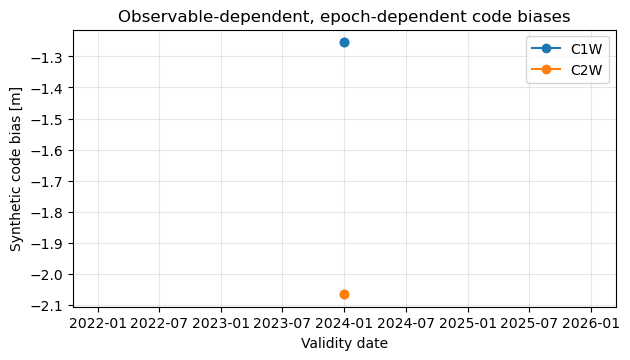

In [5]:
dates=[datetime(2024,1,1,0),datetime(2024,1,1,23)]
for day in dates:
    result = reader.sat_bias('G21', day)
    print(f'{day.date()}: C1W={result["C1W"]:+.2f} ns, '
          f'C2W={result["C2W"]:+.2f} ns')
try:
    reader.sat_bias('G21')
except ValueError as exc:
    print('Expected ambiguity check:', exc)

fig, ax = plt.subplots(figsize=(7.0, 3.6))
for code in ('C1W','C2W'):
    ax.plot([d.date() for d in dates],
            [reader.sat_bias('G21',d)[code]*1e-9*gs.C for d in dates],
            'o-', label=code)
ax.set(xlabel='Validity date', ylabel='Synthetic code bias [m]',
       title='Observable-dependent, epoch-dependent code biases')
ax.grid(alpha=.3)
ax.legend()
plt.show()

### Remember

- Use the **exact code observable** from the RINEX file (`C1W` is not interchangeable with `C1C`).
- Select the correct satellite, epoch and clock/bias convention. `Bsinex.sat_bias(sat, epoch)` returns **nanoseconds**, not metres.
- The ionosphere-free combination eliminates first-order ionospheric refraction, **not** hardware biases. OSB corrections remain relevant.

Reference: [IGS Bias-SINEX format](https://igs.org/formats-and-standards/).